#  Reinforcement Learning

> *Reinforcement learning is an area of machine learning inspired by behaviorist psychology, concerned with how software agents ought to take **actions in an environment** so as to maximize some notion of **cumulative reward**. (Source: Wikipedia)*

Reinforcement learning provides the capacity for us not only to teach an artificial agent how to act, but to allow it to learn through it’s own interactions with an environment.

By combining the complex representations that deep neural networks can learn with the goal-driven learning of an RL agent, computers have accomplished some amazing feats, like beating humans at over a dozen Atari games, and defeating the Go world champion.

RL algorithms must enable the agent to learn the correct pairings itself through the use of *observations*, *rewards*, and *actions*.

Typical aspects of a task that make it an RL problem are the following:
1. Different actions yield different rewards. For example, when looking for treasure in a maze, going left may lead to the treasure, whereas going right may lead to a pit of snakes.
2. Rewards are delayed over time. This just means that even if going left in the above example is the right things to do, we may not know it till later in the maze.
3. Reward for an action is conditional on the state of the environment. Continuing the maze example, going left may be ideal at a certain fork in the path, but not at others.


## Multi-armed bandit

The simplest reinforcement learning problem is the multi-armed bandit. Essentially, there are $n$-many slot machines, each with a different fixed payout probability.

The goal is to discover the machine with the best payout, and maximize the returned reward by always choosing it.

<img src="https://github.com/DataScienceUB/DeepLearningMaster2019/blob/master/images/slot.jpg?raw=1" alt="" style="width: 400px;"/>

This question has been the subject of active research since the 1950s, and many variations have been studied.


### Epsilon-greedy

The most straightforward algorithm for continuously balancing exploration with exploitation is called “epsilon-greedy”.

Here, we pull a randomly chosen arm a fraction $\epsilon$ of the time. The other $1-\epsilon$ of the time, we pull the arm which we estimate to be the most profitable. As each arm is pulled and rewards are received, our estimates of arm values are updated.

This method can be thought of a a continuous testing setup, where we devote a fraction $\epsilon$ of our resources to testing.

The following python code implements a simple 10-Armed Bandit using the epsilon-greedy algorithm.

The payout rate of the arms are normally distributed with $\mu = 0$ and $\sigma = 1$. Gaussian noise is also added to the rewards, also with $\mu = 0$ and $\sigma = 1$.

In [1]:
import numpy as np
import seaborn
from tqdm import tqdm

class Bandit:
    def __init__(self):

        self.arm_values = np.array([2,0,3,-7,0,0,-4,0,1,100]) #arm values

        #self.arm_values = np.random.normal(0,1,10) #arm values

        self.K = np.zeros(10)                      #action counter
        self.est_values = np.zeros(10)             #estimated values

    def get_reward(self,action):                   #get noisy reward from machine "action"
        noise = 1*np.random.normal(0,1)            # more noise
        #noise = np.random.normal(0,1)

        reward = self.arm_values[action] + noise

        return reward

    def choose_eps_greedy(self,epsilon):           #exploitation or exploration decision
        rand_num = abs(np.random.random())
        if epsilon>rand_num:
            return np.random.randint(10)           #exploration
        else:
            return np.argmax(self.est_values)      #exploitation

    def update_est(self,action,reward, smoothing = False):            #estimation of the value of an action
        self.K[action] += 1
        self.weight = 0.01                           # exponential smoothing weight
        alpha = 1./self.K[action]


        # self.weight - smoothing parameter
        # alpha - averaging constant.
        # Smoothing will not much affect the result in this perticular case but generally is more stable.
        # Below you can see modification with smoothing:
        if smoothing:
          if self.K[action] == 1:
            self.est_values[action] = reward
          elif self.K[action] > 1:
            self.est_values[action] = (self.weight * reward + (1-self.weight)*self.est_values[action]) # smoothing

        self.est_values[action] += alpha * (reward - self.est_values[action]) # average value evaluation


a= Bandit()
print("The arm values of the 10 machines are: \n",a.arm_values)
index = 0
print(f"The reward if we play {index+1} machine is: \n",a.get_reward(9))


The arm values of the 10 machines are: 
 [  2   0   3  -7   0   0  -4   0   1 100]
The reward if we play 1 machine is: 
 99.92501934104222


How are we estimating the value of an action?

If by the $t$-th time step action $a$ has been chosen $K_a$ times prior to $t$, yielding rewards
$R_1, R_2, . . . , R_{Ka}$, then its value is estimated to be:

$$
Q_t(a) = \frac{R_1 + R_2 + . . .+ R_{Ka}}{K_a}
$$

A problem with this straightforward implementation is that its memory and computational requirements grow over time without
bound (we have to maintain, for each action $a$, a record of all the rewards that have followed the
selection of that action), but we can derive an incremental formula for computing averages with small, constant computation
required to process each new reward.

\begin{eqnarray*}
Q_{k+1} & = & \frac{1}{k+1} \sum_{i=1}^{k+1} R_i \\
  & = & \frac{1}{k+1} \left( R_{k+1} + \sum_{i=1}^k R_i
\right) \\
  & = & \frac{1}{k+1} \left( R_{k+1} + kQ_k + Q_k - Q_k
\right) \\
  & = & \frac{1}{k+1} \left(R_{k+1} + (k+1) Q_k - Q_k
\right) \\
  & = & Q_k + \frac{1}{k+1} \left( R_{k+1} - Q_k \right)
\end{eqnarray*}



In [2]:
def experiment(bandit,Npulls,epsilon, smoothing = False):
    history = []
    for i in range(Npulls):
        action = bandit.choose_eps_greedy(epsilon)
        R = bandit.get_reward(action)
        bandit.update_est(action,R, smoothing)
        history.append(R)
    return np.array(history)

Let's make three different experiments: $\epsilon = 0$, $\epsilon = 0.1$ and $\epsilon = 0.01$. Data will be averages over the number of experiments Nexp

In [3]:
Nexp = 100 # number of experiments
Npulls = 5000 # number of pullings during 1 experiment
avg_outcome_eps0p0_s = np.zeros(Npulls)
avg_outcome_eps0p01_s = np.zeros(Npulls)
avg_outcome_eps0p1_s = np.zeros(Npulls)
avg_outcome_eps0p5_s = np.zeros(Npulls)

for i in tqdm(range(Nexp)):
    bandit = Bandit()
    avg_outcome_eps0p0_s += experiment(bandit,Npulls,0.0, False)
print(bandit.est_values)

for i in tqdm(range(Nexp)):
    bandit = Bandit()
    avg_outcome_eps0p01_s += experiment(bandit,Npulls,0.01, False)
print(bandit.est_values)

for i in tqdm(range(Nexp)):
    bandit = Bandit()
    avg_outcome_eps0p1_s += experiment(bandit,Npulls,0.1, False)
print(bandit.est_values)

for i in tqdm(range(Nexp)):
    bandit = Bandit()
    avg_outcome_eps0p5_s += experiment(bandit,Npulls,0.5, False)
print(bandit.est_values)



avg_outcome_eps0p0_s /= np.float64(Nexp)
avg_outcome_eps0p01_s /= np.float64(Nexp)
avg_outcome_eps0p1_s /= np.float64(Nexp)
avg_outcome_eps0p5_s /= np.float64(Nexp)


100%|██████████| 100/100 [00:10<00:00,  9.64it/s]


[2.00985097 0.         0.         0.         0.         0.
 0.         0.         0.         0.        ]


100%|██████████| 100/100 [00:07<00:00, 12.90it/s]


[ 2.06783055e+00 -1.16427092e-01  2.99777072e+00 -6.96227480e+00
  2.77072874e-02 -5.38982515e-01 -3.82761985e+00 -2.06206646e-01
  1.85454107e+00  1.00020543e+02]


100%|██████████| 100/100 [00:07<00:00, 14.10it/s]


[ 1.99726019e+00  2.02980889e-01  2.97557287e+00 -7.15055457e+00
  5.36135924e-02 -4.68230605e-02 -3.76859664e+00 -2.08345837e-01
  8.95338550e-01  1.00019306e+02]


100%|██████████| 100/100 [00:07<00:00, 13.06it/s]

[ 2.05643483e+00 -1.26347385e-02  2.98602445e+00 -6.92714035e+00
 -5.85081640e-02 -3.12838423e-02 -3.97557097e+00 -2.61704510e-02
  1.03786480e+00  1.00003431e+02]


In [4]:
print(bandit.arm_values)

[  2   0   3  -7   0   0  -4   0   1 100]


[  2   0   3  -7   0   0  -4   0   1 100]


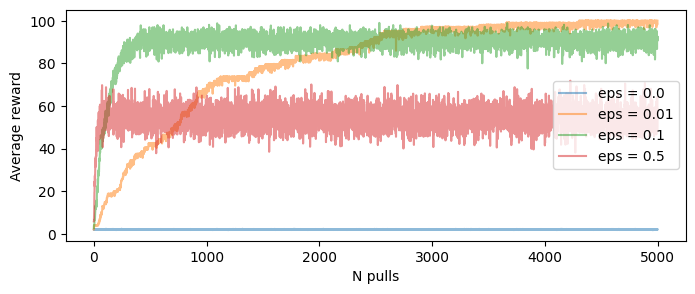

In [5]:
# plot results
import matplotlib.pyplot as plt
print(bandit.arm_values)
plt.plot(avg_outcome_eps0p0_s,label="eps = 0.0", alpha=0.5)
plt.plot(avg_outcome_eps0p01_s,label="eps = 0.01", alpha=0.5)
plt.plot(avg_outcome_eps0p1_s,label="eps = 0.1", alpha=0.5)
plt.plot(avg_outcome_eps0p5_s,label="eps = 0.5", alpha=0.5)
#plt.ylim(0,max(avg_outcome_eps0p01)+1)
#plt.title("With smoothing")
plt.xlabel("N pulls")
plt.ylabel("Average reward")
plt.legend()
plt.gcf().set_size_inches((8,3))
plt.show()